In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score, f1_score, recall_score, confusion_matrix, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

In [ ]:
df=pd.read_csv('/content/Social_Network_Ads.csv')
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [ ]:
df.isnull().sum()

,0
User ID,0
Gender,0
Age,0
EstimatedSalary,0
Purchased,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [ ]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [ ]:
df.shape

(400, 5)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
le=LabelEncoder()
df['Gender']=le.fit_transform(df['Gender'])
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,1,19,19000,0
1,15810944,1,35,20000,0
2,15668575,0,26,43000,0
3,15603246,0,27,57000,0
4,15804002,1,19,76000,0
...,...,...,...,...,...
395,15691863,0,46,41000,1
396,15706071,1,51,23000,1
397,15654296,0,50,20000,1
398,15755018,1,36,33000,0


In [ ]:
X=df[["Gender","Age","EstimatedSalary"]]
Y=df['Purchased']
print(X)
print(Y)

     Gender  Age  EstimatedSalary
0         1   19            19000
1         1   35            20000
2         0   26            43000
3         0   27            57000
4         1   19            76000
..      ...  ...              ...
395       0   46            41000
396       1   51            23000
397       0   50            20000
398       1   36            33000
399       0   49            36000

[400 rows x 3 columns]
0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    0
399    1
Name: Purchased, Length: 400, dtype: int64


In [ ]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [ ]:
scalar=StandardScaler()
X_train_scaled=scalar.fit_transform(X_train)
X_test_scaled=scalar.transform(X_test)

In [ ]:
lo=LogisticRegression()
lo.fit(X_train_scaled,Y_train)

LogisticRegression()

In [ ]:
y_pred=lo.predict(X_test_scaled)
y_pred

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0])

<Axes: >

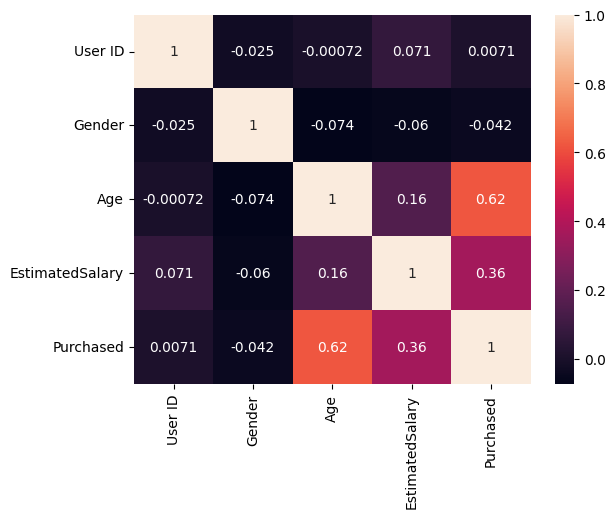

In [ ]:
sns.heatmap(df.corr(),annot=True)

In [ ]:
cm=confusion_matrix(Y_test,y_pred)
cm

array([[50,  2],
       [ 7, 21]])

In [ ]:
print("Accuracy is:\t",accuracy_score(Y_test,y_pred)*100,"%")
print("Precision is:\t",precision_score(Y_test,y_pred)*100,"%")
print("Recall is:\t",recall_score(Y_test,y_pred)*100,"%")
print("F1 score is:\t",f1_score(Y_test,y_pred)*100,"%")


Accuracy is:	 88.75 %
Precision is:	 91.30434782608695 %
Recall is:	 75.0 %
F1 score is:	 82.35294117647058 %


In [ ]:
TP,FN,FP,TN=cm.ravel()
print("True Positive:\t",TP)
print("False Negative:\t",FN)
print("False Positive:\t",FP)
print("True Negative:\t",TN)

True Positive:	 50
False Negative:	 2
False Positive:	 7
True Negative:	 21


In [ ]:
A=(TP+TN)/(TP+TN+FP+FN)
P=(TP)/(TP+FP)
R=(TP)/(TP+FN)
f1=(2*P*R)/(P+R)
print("Accuracy is:\t",A*100,"%")
print("Precision is:\t",P*100,"%")
print("Recall is:\t",R*100,"%")
print("F1 score is:\t",f1*100,"%")

Accuracy is:	 88.75 %
Precision is:	 87.71929824561403 %
Recall is:	 96.15384615384616 %
F1 score is:	 91.74311926605505 %


Text(0, 0.5, 'True Positive Rate')

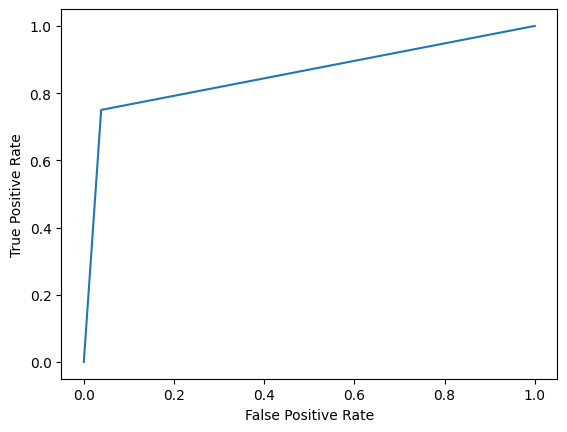

In [ ]:
roc=roc_curve(Y_test,y_pred)
fpr,tpr,_=roc
plt.plot(fpr,tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")